<a href="https://colab.research.google.com/github/davichomendez1901-byte/Simulaci-n-Remix/blob/main/MCMC_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MCMC: Algoritmo de Metropolis.
###Simulación de una distribución bidimensional mediante cadenas de Markov.

**Materia** Simulacion II

**Alumno** Maya Mendez David Emilio.


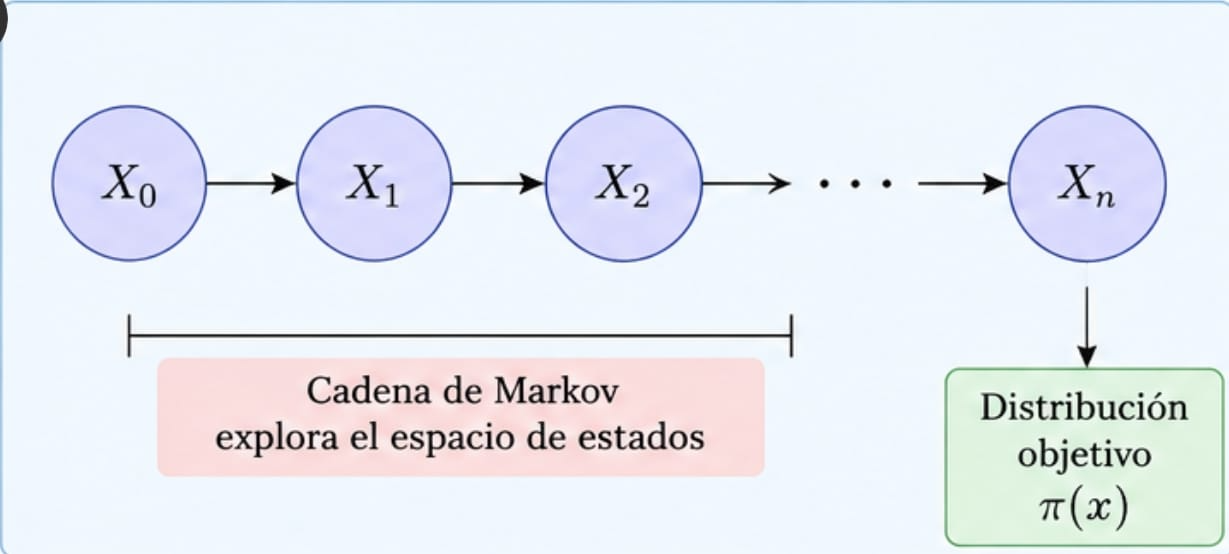

##Introducción
Los métodos de Monte Carlo vía cadenas de Markov, conocidos como **MCMC** permiten generar muestras de una distribución de probabilidad utilizando una cadena de Markov.

 En este trabajo se implementará el *algoritmo de Metropolis*, cuyo objetivo
es construir una cadena de Markov que tenga como distribución estacionaria
una distribución objetivo dada.

El algoritmo será probado utilizando una función de densidad en dos
dimensiones, de acuerdo con el ejemplo visto en clase.

## Objetivo

Implementar en Python el algoritmo de Metropolis para generar una muestra
de una distribución bidimensional.

A partir de un estado inicial, se propondrán nuevos valores mediante una
caminata aleatoria. Cada propuesta será aceptada o rechazada de acuerdo
con la razón de probabilidades definida por el algoritmo de Metropolis.

Finalmente, se analizará la muestra obtenida mediante gráficas para
comprobar que la cadena reproduce el comportamiento de la distribución
objetivo.

## 1. Algoritmo de Metropolis

Sea una variable aleatoria

$$
X=(X_1,X_2)
$$

con una distribución objetivo cuya función de densidad es proporcional a

$$
f(x).
$$

El algoritmo de Metropolis permite construir una cadena de Markov

$$
\{X_t\}_{t=0}^{n}
$$

cuya distribución estacionaria corresponde a la distribución objetivo.

### Constante de normalización

Una ventaja del algoritmo de Metropolis es que no es necesario conocer
explícitamente la constante de normalización de la distribución.

Si

$$
f(x)=C\,g(x),
$$

entonces al calcular la razón

$$
\frac{f(y)}{f(x)}
$$

se obtiene

$$
\frac{C g(y)}{C g(x)}
=
\frac{g(y)}{g(x)}.
$$

Por esta razón, la constante $C$ se cancela y es suficiente trabajar con
una función proporcional a la densidad objetivo.

## 2. Distribución objetivo

Para comprobar el algoritmo de Metropolis se utilizará la función
bidimensional vista en clase:

$$
f(x_1,x_2)
=
c\exp\left[
-\frac{x_1^2+x_1x_2+x_2^2-2x_1-2x_2}{2}
\right].
$$

donde $c$ es la constante de normalización.

Debido a que el algoritmo de Metropolis utiliza el cociente

$$
\frac{f(Y)}{f(X_t)},
$$

la constante $c$ aparece tanto en el numerador como en el denominador y
se cancela. Por lo tanto, para implementar el algoritmo es suficiente
trabajar con

$$
g(x_1,x_2)
=
\exp\left[
-\frac{x_1^2+x_1x_2+x_2^2-2x_1-2x_2}{2}
\right].
$$

In [1]:
import numpy as np

In [2]:
def f(x):
    # Separamos las dos componentes del vector x
    x1 = x[0]
    x2 = x[1]

    # Exponente de la función objetivo
    exponente = -(x1**2 + x1*x2 + x2**2 - 2*x1 - 2*x2) / 2

    # No incluimos la constante c porque se cancela en Metropolis
    return np.exp(exponente)

In [3]:
x = np.array([1.0, 2.0])

print(f(x))

0.6065306597126334


In [5]:
# Generar una propuesta usando caminata aleatoria normal
sigma = 1
z = np.random.normal(0, sigma, 2)

# Nuevo punto propuesto
y = x + z

# Probabilidad de aceptación
alpha = min(f(y) / f(x), 1)

# Número uniforme para decidir si se acepta o rechaza
u = np.random.uniform(0, 1)

# Regla de Metropolis
if u < alpha:
    x_nuevo = y
else:
    x_nuevo = x

# resultados
print("x actual =", x)
print("z =", z)
print("y propuesto =", y)
print("alpha =", alpha)
print("u =", u)
print("x nuevo =", x_nuevo)

x actual = [1. 2.]
z = [1.42083235 2.24138825]
y propuesto = [2.42083235 4.24138825]
alpha = 5.034928565649761e-05
u = 0.6861702175144986
x nuevo = [1. 2.]


In [6]:
# Número de iteraciones
n = 10000

# Punto inicial
x = np.array([1.0, 2.0])

# Lista donde guardaremos la cadena
cadena = [x.copy()]

# Contador de propuestas aceptadas
aceptados = 0

for i in range(n):

    # Propuesta mediante caminata aleatoria
    z = np.random.normal(0, sigma, 2)
    y = x + z

    # Probabilidad de aceptación
    alpha = min(f(y) / f(x), 1)

    # Número uniforme
    u = np.random.uniform(0, 1)

    # Regla de Metropolis
    if u < alpha:
        x = y
        aceptados += 1

    # Guardamos el estado de la cadena
    cadena.append(x.copy())

# Convertimos la lista a arreglo
cadena = np.array(cadena)

print("Número de aceptados =", aceptados)
print("Tasa de aceptación =", aceptados / n)
print("Tamaño de la cadena =", len(cadena))

Número de aceptados = 5577
Tasa de aceptación = 0.5577
Tamaño de la cadena = 10001


In [7]:
import matplotlib.pyplot as plt


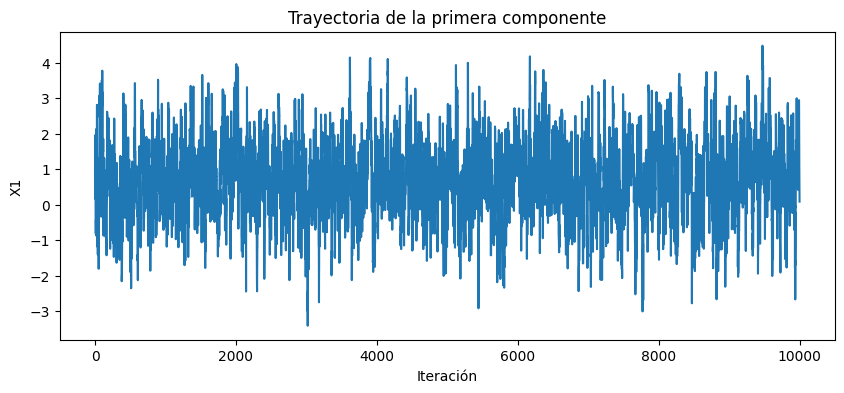

In [8]:
plt.figure(figsize=(10,4))

plt.plot(cadena[:,0])

plt.xlabel("Iteración")
plt.ylabel("X1")
plt.title("Trayectoria de la primera componente")

plt.show()

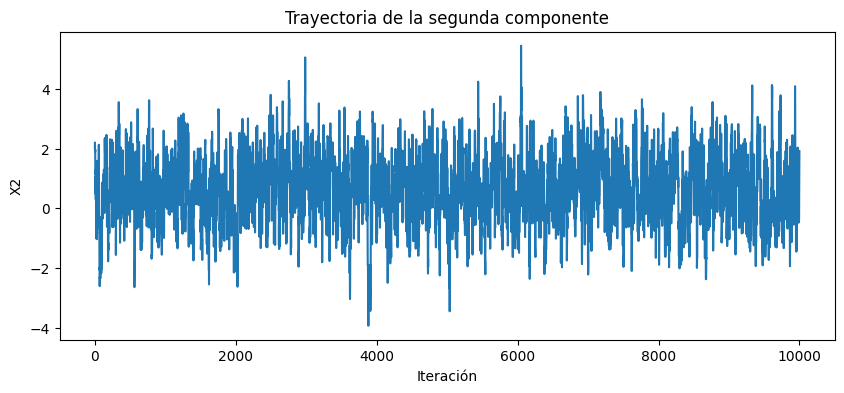

In [9]:
plt.figure(figsize=(10,4))

plt.plot(cadena[:,1])

plt.xlabel("Iteración")
plt.ylabel("X2")
plt.title("Trayectoria de la segunda componente")

plt.show()

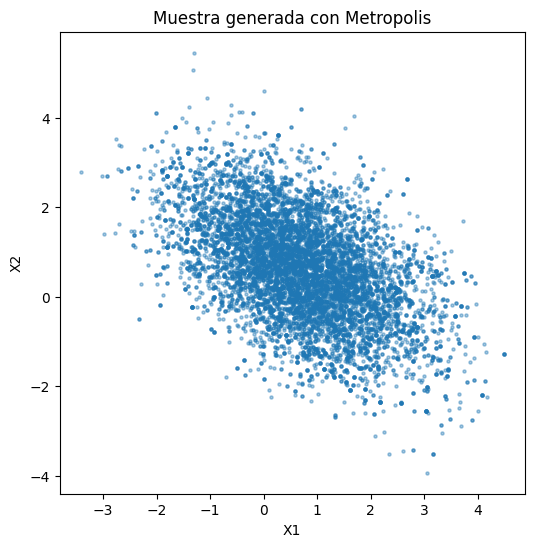

In [10]:
plt.figure(figsize=(6,6))

plt.scatter(cadena[:,0], cadena[:,1], s=5, alpha=0.4)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Muestra generada con Metropolis")

plt.show()

### Interpretación

La muestra generada presenta una forma elíptica con inclinación negativa,
lo que indica dependencia negativa entre las variables $X_1$ y $X_2$.

La mayor concentración de puntos se encuentra alrededor de $(0.67,0.67)$,
lo cual es consistente con la distribución objetivo. Esto proporciona una
primera evidencia gráfica de que el algoritmo de Metropolis está generando
muestras de la distribución deseada.

In [11]:
# Eliminamos las primeras iteraciones
burn_in = 1000
muestra = cadena[burn_in:]

# Medias estimadas
media_x1 = np.mean(muestra[:, 0])
media_x2 = np.mean(muestra[:, 1])

print("Media de X1 =", media_x1)
print("Media de X2 =", media_x2)

Media de X1 = 0.7007129983094603
Media de X2 = 0.6545546681934296


### Comparación con la media teórica

Después de eliminar las primeras 1000 iteraciones como periodo de
burn-in, se obtuvieron las siguientes medias muestrales:

$$
\bar X_1 \approx 0.701,
\qquad
\bar X_2 \approx 0.655.
$$

Para la distribución objetivo, la media teórica de ambas componentes es

$$
E[X_1]=E[X_2]=\frac{2}{3}\approx0.667.
$$

Los valores obtenidos mediante Metropolis son cercanos a los valores
teóricos, lo cual indica que la cadena está reproduciendo adecuadamente
la distribución objetivo.

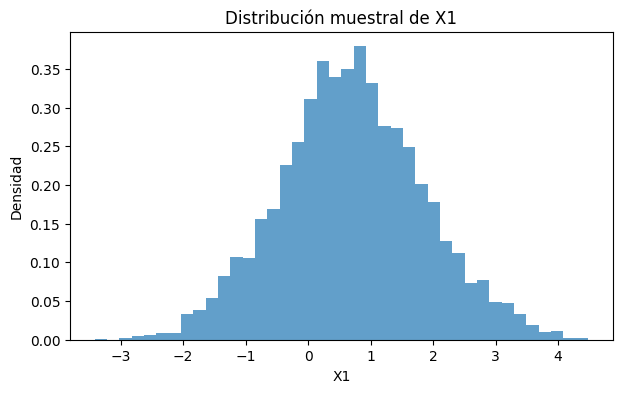

In [12]:
plt.figure(figsize=(7,4))

plt.hist(muestra[:,0], bins=40, density=True, alpha=0.7)

plt.xlabel("X1")
plt.ylabel("Densidad")
plt.title("Distribución muestral de X1")

plt.show()

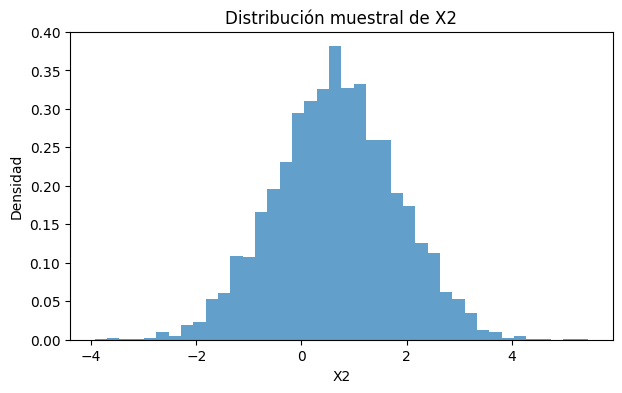

In [13]:
plt.figure(figsize=(7,4))

plt.hist(muestra[:,1], bins=40, density=True, alpha=0.7)

plt.xlabel("X2")
plt.ylabel("Densidad")
plt.title("Distribución muestral de X2")

plt.show()

In [14]:
# Matriz de covarianzas estimada con la muestra
cov_muestral = np.cov(muestra[:, 0], muestra[:, 1])

print("Matriz de covarianzas estimada:")
print(cov_muestral)

# Matriz teórica
cov_teorica = np.array([
    [4/3, -2/3],
    [-2/3, 4/3]
])

print("\nMatriz de covarianzas teórica:")
print(cov_teorica)

Matriz de covarianzas estimada:
[[ 1.33197336 -0.69779923]
 [-0.69779923  1.34641857]]

Matriz de covarianzas teórica:
[[ 1.33333333 -0.66666667]
 [-0.66666667  1.33333333]]


### Comparación de covarianzas

La matriz de covarianzas obtenida mediante la simulación presenta valores
cercanos a los valores teóricos:

$$
\Sigma=
\begin{pmatrix}
1.333 & -0.667\\
-0.667 & 1.333
\end{pmatrix}.
$$

En particular, la covarianza negativa confirma la relación inversa entre
$X_1$ y $X_2$ observada en la gráfica bidimensional.

Las pequeñas diferencias se deben a que los valores fueron obtenidos mediante
una muestra aleatoria finita generada por el algoritmo de Metropolis.

## Conclusión

Se implementó el algoritmo de Metropolis para generar muestras de una
distribución bidimensional.

La cadena obtenida presentó una tasa de aceptación adecuada y, después de
eliminar las primeras iteraciones mediante un periodo de burn-in, las medias
muestrales resultaron cercanas a los valores teóricos esperados.

Además, la matriz de covarianzas estimada fue similar a la matriz teórica,
conservando la covarianza negativa entre $X_1$ y $X_2$. Esto también se observó
gráficamente mediante la forma elíptica e inclinada de la nube de puntos.

Por lo tanto, los resultados numéricos y gráficos indican que el algoritmo de
Metropolis implementado reproduce de manera adecuada la distribución objetivo.